# 13 — HOG, dlib e detectores treináveis

**EP · Data Science Knowledge Base | Análise e Classificação de Imagens | Notebook 13/16**

**Pré-requisitos:** Python, NumPy e fundamentos de visualização; consulte os capítulos anteriores quando necessário.

**Escopo de validação:** O laboratório HOG básico não exige dlib; detectores dlib são opcionais e exigem instalação/validação separadas.

---

> **Biblioteca pessoal de Ciência de Dados** · Análise e Classificação de Imagens · Capítulo 13/16

> **Execução:** células principais executadas localmente no JupyterLab em 14/11/2026, conforme confirmação do autor; teste complementar isolado dlib 20.0.1 aprovado com detector HOG em imagem vazia (não mede acurácia facial).


### Materiais complementares

- [Guia Técnico](./reference_materials/13_hog_dlib_detectores.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_hog_dlib_detectores.pdf)


## Como estudar este capítulo

1. Leia os fundamentos e consulte o Guia Técnico correspondente.
2. Reinicie o kernel e execute as células obrigatórias na sequência.
3. Confira tabelas, visualizações, saídas e limitações descritas no notebook.
4. Resolva o exercício antes de consultar a solução; execute laboratórios opcionais apenas em ambiente compatível.

**Pré-requisitos transversais:** Programação Python (01), visualização de dados (02), Estatística (03), Machine Learning (05) e Deep Learning (07), conforme o capítulo.


## Objetivos de aprendizagem

Explicar como HOG vira detector e comparar treinamento de classificador com localização.

Ao concluir, você deverá ser capaz de **explicar a técnica**, **executar o exemplo**, **interpretar limitações** e **justificar escolhas de avaliação**.

## Fundamentos conceituais

Um detector de janela deslizante combina descritor HOG com classificador e busca em posições/escalas. O dlib implementa detectores clássicos, mas compilação e webcam não devem ser exigidas. Treinos históricos de frutas ilustram rotulagem de caixas, negativos difíceis, NMS e validação por imagens não correlacionadas. Um classificador de crops não equivale a um detector completo.

### Conceito matemático

$$score(window)=w^\top HOG(window)+b$$

A fórmula expressa o mecanismo principal do capítulo. Identifique unidades, dimensões e hipóteses antes de aplicar uma implementação.

## Experimento 1 — construção e medidas

Execute em kernel limpo. Exemplos usam datasets de bibliotecas instaláveis e não requerem download de arquivos externos.

In [1]:
import numpy as np
from skimage.feature import hog
from skimage.data import camera
im=camera();patch=im[80:208,80:208]
vec,vis=hog(patch,orientations=9,pixels_per_cell=(8,8),cells_per_block=(2,2),visualize=True)
print('janela:',patch.shape,'HOG:',len(vec),'visualização:',vis.shape)

janela: (128, 128) HOG: 8100 visualização: (128, 128)


## Experimento 2 — visualização, comparação ou validação

Observe não apenas o valor obtido, mas o que o experimento **realmente demonstra**.

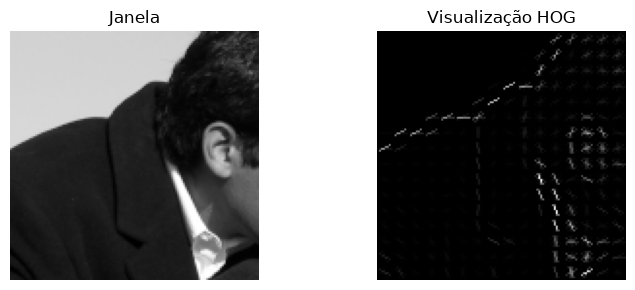

In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,2,figsize=(8,3))
for a,img,title in zip(ax,[patch,vis],['Janela','Visualização HOG']):a.imshow(img,cmap='gray');a.set_title(title);a.axis('off')
plt.tight_layout();plt.show()

## Interpretação técnica

O exemplo extrai uma característica, mas não treina nem valida detector de frutas; arquivos antigos ficam preservados para eventual estudo de caso.

### Conexão com o acervo

Em vez de repetir capítulos de SVM, PCA, métricas e backpropagation, este notebook concentra a aplicação e limitações **em imagens**. Revisite as Disciplinas 05 e 07 para demonstrações matemáticas mais extensas.

## Exercício resolvido

**Problema:** Por que usar supressão de não máximos (NMS)?

**Resolução comentada:** Para reduzir múltiplas caixas redundantes que descrevem o mesmo objeto.

**Para praticar:** modifique um parâmetro do exemplo, registre a hipótese antes de executar e compare resultado, qualidade visual e custo computacional.

## Erros comuns e limitações

O dataset de frutos pode ter vazamento se imagens quase iguais aparecem em treino e teste.

- Nunca ajustar parâmetros em cima do conjunto de teste final.
- Não confundir demonstração com validação científica completa.
- Documentar versões, fontes de dados e condições de execução.
- Não redistribuir fotografias de rostos ou datasets históricos sem licença e autorização.

## Consulta rápida

- **Pergunta-chave:** Explicar como HOG vira detector e comparar treinamento de classificador com localização.
- **Mecanismo:** Um detector de janela deslizante combina descritor HOG com classificador e busca em posições/escalas.
- **Equação:** $score(window)=w^\top HOG(window)+b$
- **Verificação:** interpretar formato dos dados, hipótese e saída antes de utilizar em um projeto.

### Referências de estudo

- Apresentações originais da disciplina (PDF consolidado).
- Documentação: [scikit-image](https://scikit-image.org/docs/stable/), [OpenCV](https://docs.opencv.org/4.x/), [scikit-learn](https://scikit-learn.org/stable/), conforme o capítulo.
- Para CNNs: [Keras](https://keras.io/).

## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** dependência dlib. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **dependência dlib** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **dependência dlib** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.
